In [ ]:
import os, math, time, copy, random, pickle
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torchvision.datasets import CIFAR10

device = "cuda" if torch.cuda.is_available() else "cpu"
EPOCHS = 60
SEEDS = [0, 1, 2]
FINAL_SEEDS = [10, 11, 12]
CLASSES = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

In [ ]:
train_set = CIFAR10("./data", train=True, download=True)
test_set = CIFAR10("./data", train=False, download=True)
x_all, y_all = train_set.data.transpose(0, 3, 1, 2), np.array(train_set.targets)
x_te, y_te = test_set.data.transpose(0, 3, 1, 2), np.array(test_set.targets)
tt = lambda a: torch.from_numpy(a).float() / 255.


rng = np.random.RandomState(1234); tr, va = [], []
for c in range(10):
    idx = rng.permutation(np.where(y_all == c)[0])[:50]
    tr += list(idx[:40]); va += list(idx[40:])
X_train, y_train = tt(x_all[tr]).to(device), torch.tensor(y_all[tr]).to(device)
X_val, y_val = tt(x_all[va]).to(device), torch.tensor(y_all[va]).to(device)
X_clean, y_clean = tt(x_te), torch.tensor(y_te)
MEAN = X_train.mean((0, 2, 3)).view(1, 3, 1, 1).cpu(); STD = X_train.std((0, 2, 3)).view(1, 3, 1, 1).cpu()
print(X_train.shape, X_val.shape, X_clean.shape)
print("train per class:", torch.bincount(y_train.cpu()).tolist(), "| val per class:", torch.bincount(y_val.cpu()).tolist())

torch.Size([400, 3, 32, 32]) torch.Size([100, 3, 32, 32]) torch.Size([10000, 3, 32, 32])
train per class: [40, 40, 40, 40, 40, 40, 40, 40, 40, 40] | val per class: [10, 10, 10, 10, 10, 10, 10, 10, 10, 10]


In [ ]:
def affine(x, ang, scale, shift, pad):
    B = x.size(0); a = ang * math.pi / 180
    theta = torch.zeros(B, 2, 3, device=x.device)
    theta[:, 0, 0], theta[:, 0, 1] = torch.cos(a) / scale, -torch.sin(a) / scale
    theta[:, 1, 0], theta[:, 1, 1] = torch.sin(a) / scale, torch.cos(a) / scale
    theta[:, :, 2] = shift
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    return F.grid_sample(x, grid, padding_mode=pad, align_corners=False)

def gaussian_blur(x, sigma, k=5):
    ax = torch.arange(k, device=x.device).float() - (k - 1) / 2
    g = torch.exp(-ax ** 2 / (2 * sigma ** 2)); g = g / g.sum()
    ker = (g[:, None] * g[None, :])[None, None].repeat(3, 1, 1, 1)
    return F.conv2d(F.pad(x, (k // 2,) * 4, mode="reflect"), ker, groups=3)

def hidden_corruption(x, R, p=0.5):
    """PLACEHOLDER hidden corruption (random colour-channel swap). Replace with the one your professor provides."""
    B = x.size(0)
    perms = torch.tensor([[1, 0, 2], [2, 1, 0], [0, 2, 1], [1, 2, 0], [2, 0, 1]])
    swapped = x[torch.arange(B)[:, None], perms[(R(B) * 5).long().clamp(max=4)]]
    return torch.where((R(B) < p).view(-1, 1, 1, 1), swapped, x)

def make_shifted(x, seed=2024, only_swap=False, p_swap=0.5):
    """Fixed-seed corruption of the clean test set: rotation +-25, brightness/contrast, blur, noise, ~25% occluder + hidden corruption."""
    g = torch.Generator().manual_seed(seed); B = x.size(0)
    R = lambda *s: torch.rand(*s, generator=g); v = lambda t: t.view(-1, 1, 1, 1); out = x.clone()
    if not only_swap:
        out = affine(out, (R(B) * 2 - 1) * 25, torch.ones(B), torch.zeros(B, 2), "zeros")
        m = out.mean((1, 2, 3), keepdim=True)
        out = (v(0.5 + R(B)) * (out - m) + m + v((R(B) * 2 - 1) * 0.3)).clamp(0, 1)
        out = torch.where(v(R(B) < 0.4), gaussian_blur(out, 1.0), out)
        out = torch.where(v(R(B) < 0.4), (out + 0.06 * torch.randn(out.shape, generator=g)).clamp(0, 1), out)
        h = (8 + R(B) * 25).long(); w = (256 / h).round().long().clamp(max=32)           # occluder, ~25 % of the image
        y0 = (R(B) * (33 - h)).long(); x0 = (R(B) * (33 - w)).long()
        ys, xs = torch.arange(32).view(1, 32, 1), torch.arange(32).view(1, 1, 32)
        box = (ys >= y0.view(-1, 1, 1)) & (ys < (y0 + h).view(-1, 1, 1)) & (xs >= x0.view(-1, 1, 1)) & (xs < (x0 + w).view(-1, 1, 1))
        out = torch.where(box.unsqueeze(1), R(B, 1, 1, 1).expand_as(out), out)
    return hidden_corruption(out, R, p_swap)

if os.path.exists("shifted_test.npz"):
    d = np.load("shifted_test.npz"); X_shift, y_shift = tt(d["x"]).permute(0, 3, 1, 2), torch.tensor(d["y"])
else:
    X_shift, y_shift = make_shifted(X_clean), y_clean.clone()
print(X_shift.shape)

torch.Size([10000, 3, 32, 32])


In [ ]:
print(pd.DataFrame([
    ["train_small", "50 images per class chosen with np.random.RandomState(1234) from the 50,000 CIFAR-10 training images"],
    ["train / validation split", "per class: first 40 -> train (400), last 10 -> validation (100)"],
    ["clean_test", "original 10,000 CIFAR-10 test images (never used for training, validation or tuning)"],
    ["shifted_test", "make_shifted(clean_test, seed=2024): rotation +-25 deg, brightness/contrast, blur, noise, ~25% occlusion, hidden corruption"],
    ["hidden-corruption-only test", "make_shifted(clean_test, seed=77, only_swap=True)"],
    ["hyper-parameter search seed", "99 (validation split only)"],
    ["training seeds (ablation)", str(SEEDS)],
    ["training seeds (final model)", str(FINAL_SEEDS)]], columns=["Item", "Seed / rule"]).to_string(index=False))

                        Item                                                                                                                 Seed / rule
                 train_small                        50 images per class chosen with np.random.RandomState(1234) from the 50,000 CIFAR-10 training images
    train / validation split                                                             per class: first 40 -> train (400), last 10 -> validation (100)
                  clean_test                                        original 10,000 CIFAR-10 test images (never used for training, validation or tuning)
                shifted_test make_shifted(clean_test, seed=2024): rotation +-25 deg, brightness/contrast, blur, noise, ~25% occlusion, hidden corruption
 hidden-corruption-only test                                                                           make_shifted(clean_test, seed=77, only_swap=True)
 hyper-parameter search seed                                                      

In [ ]:
def aug_geometric(x):
    B, dev = x.size(0), x.device
    ang = (torch.rand(B, device=dev) * 2 - 1) * 30
    sc = torch.empty(B, device=dev).uniform_(0.9, 1.1)
    sh = (torch.rand(B, 2, device=dev) * 2 - 1) * 0.2
    x = affine(x, ang, sc, sh, "reflection")
    return torch.where((torch.rand(B, device=dev) < 0.5).view(-1, 1, 1, 1), x.flip(3), x)

def aug_photometric(x):
    B, dev = x.size(0), x.device
    U = lambda lo, hi: torch.empty(B, device=dev).uniform_(lo, hi).view(-1, 1, 1, 1)
    P = lambda p: (torch.rand(B, device=dev) < p).view(-1, 1, 1, 1)
    x = (x + U(-0.25, 0.25)).clamp(0, 1)
    m = x.mean((1, 2, 3), keepdim=True); x = ((x - m) * U(0.6, 1.4) + m).clamp(0, 1)
    gray = 0.299 * x[:, :1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:]
    x = (gray + U(0.5, 1.5) * (x - gray)).clamp(0, 1)
    x = torch.where(P(0.1), gray.expand_as(x), x)
    x = torch.where(P(0.3), gaussian_blur(x, float(np.random.uniform(0.6, 1.2))), x)
    return torch.where(P(0.3), (x + torch.randn_like(x) * U(0.02, 0.08)).clamp(0, 1), x)

def aug_cutout(x, p=0.7):
    B, H, W = x.shape[0], x.shape[2], x.shape[3]; dev = x.device
    area = torch.empty(B, device=dev).uniform_(0.05, 0.35) * H * W
    ar = torch.exp(torch.empty(B, device=dev).uniform_(math.log(0.5), math.log(2.0)))
    h, w = torch.sqrt(area * ar).view(-1, 1, 1), torch.sqrt(area / ar).view(-1, 1, 1)
    cy, cx = (torch.rand(B, device=dev) * H).view(-1, 1, 1), (torch.rand(B, device=dev) * W).view(-1, 1, 1)
    ys, xs = torch.arange(H, device=dev).view(1, H, 1), torch.arange(W, device=dev).view(1, 1, W)
    box = ((ys - cy).abs() < h / 2) & ((xs - cx).abs() < w / 2) & (torch.rand(B, device=dev) < p).view(-1, 1, 1)
    return torch.where(box.unsqueeze(1), torch.rand(B, 1, 1, 1, device=dev).expand_as(x), x)

def mix_batch(x, y):
    perm = torch.randperm(x.size(0), device=x.device); H = W = 32
    if random.random() < 0.5:
        lam = float(np.random.beta(0.4, 0.4)); x = lam * x + (1 - lam) * x[perm]
    else:
        lam = float(np.random.beta(1.0, 1.0)); r = math.sqrt(1 - lam); h, w = int(H * r), int(W * r)
        cy, cx = np.random.randint(H), np.random.randint(W)
        y1, y2, x1, x2 = max(cy - h // 2, 0), min(cy + h // 2, H), max(cx - w // 2, 0), min(cx + w // 2, W)
        x = x.clone(); x[:, :, y1:y2, x1:x2] = x[perm][:, :, y1:y2, x1:x2]
        lam = 1 - (y2 - y1) * (x2 - x1) / (H * W)
    return x, y, y[perm], lam

def augment(x, cfg):
    if cfg.get("geo"): x = aug_geometric(x)
    if cfg.get("photo"): x = aug_photometric(x)
    if cfg.get("cutout"): x = aug_cutout(x)
    return x

In [ ]:
class ConvBNReLU(nn.Sequential):
    def __init__(self, cin, cout, k):
        super().__init__(nn.Conv2d(cin, cout, k, padding=k // 2, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

class Inception(nn.Module):
    def __init__(self, cin, c1, c3r, c3, c5r, c5, cp):
        super().__init__()
        self.b1 = ConvBNReLU(cin, c1, 1)
        self.b2 = nn.Sequential(ConvBNReLU(cin, c3r, 1), ConvBNReLU(c3r, c3, 3))
        self.b3 = nn.Sequential(ConvBNReLU(cin, c5r, 1), ConvBNReLU(c5r, c5, 5))
        self.b4 = nn.Sequential(nn.MaxPool2d(3, 1, 1), ConvBNReLU(cin, cp, 1))
        self.out_channels = c1 + c3 + c5 + cp
    def forward(self, x):
        return torch.cat([self.b1(x), self.b2(x), self.b3(x), self.b4(x)], 1)

class Net(nn.Module):
    def __init__(self, dropout=0.4):
        super().__init__()
        self.register_buffer("mean", MEAN.clone()); self.register_buffer("std", STD.clone())
        self.stem = nn.Sequential(ConvBNReLU(3, 32, 5), nn.MaxPool2d(2), ConvBNReLU(32, 64, 3))
        self.inc1 = Inception(64, 32, 32, 48, 8, 16, 16)
        self.inc2 = Inception(112, 48, 48, 96, 16, 32, 32)
        self.fc1, self.drop, self.fc2 = nn.Linear(208, 128), nn.Dropout(dropout), nn.Linear(128, 10)
    def forward(self, x):
        x = self.stem((x - self.mean) / self.std)
        x = self.inc2(F.max_pool2d(self.inc1(x), 2))
        x = F.adaptive_avg_pool2d(x, 1).flatten(1)
        return self.fc2(self.drop(F.relu(self.fc1(x))))

n_params = sum(p.numel() for p in Net().parameters() if p.requires_grad)
print("trainable parameters:", n_params); assert n_params <= 1_000_000

trainable parameters: 142970


In [ ]:
def evaluate(model, X, y, bs=1000):
    model.eval()
    with torch.no_grad():
        lg = torch.cat([model(X[i:i + bs].to(device)) for i in range(0, len(X), bs)])
    y = y.to(device); return F.cross_entropy(lg, y).item(), (lg.argmax(1) == y).float().mean().item()

def run(cfg, seed, hp, test=True, epochs=EPOCHS, bs=50):
    set_seed(seed); model = Net(hp["dropout"]).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=hp["lr"], weight_decay=hp["wd"])
    n = len(X_train); steps = math.ceil(n / bs)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=hp["lr"], total_steps=epochs * steps, pct_start=0.15)
    ls = cfg.get("ls", 0.0); hist = {k: [] for k in ("train_loss", "train_acc", "val_loss", "val_acc")}
    best, best_state, bad = (-1, 0), None, 0
    for ep in range(epochs):
        model.train(); perm = torch.randperm(n, device=device)
        for i in range(steps):
            idx = perm[i * bs:(i + 1) * bs]
            xb, yb = augment(X_train[idx], cfg), y_train[idx]
            if cfg.get("mix") and random.random() < 0.5: xb, ya, yb2, lam = mix_batch(xb, yb)
            else: ya, yb2, lam = yb, yb, 1.0
            out = model(xb)
            loss = lam * F.cross_entropy(out, ya, label_smoothing=ls) + (1 - lam) * F.cross_entropy(out, yb2, label_smoothing=ls)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        tl, ta = evaluate(model, X_train, y_train); vl, va = evaluate(model, X_val, y_val)
        for k, val in zip(hist, (tl, ta, vl, va)): hist[k].append(val)
        if (va, -vl) > best:
            best, best_state, bad = (va, -vl), copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= 20: break
    model.load_state_dict(best_state)
    res = dict(seed=seed, model=model, hist=hist, train_acc=evaluate(model, X_train, y_train)[1], val_acc=evaluate(model, X_val, y_val)[1])
    if test: res["clean"] = evaluate(model, X_clean, y_clean)[1]; res["shifted"] = evaluate(model, X_shift, y_shift)[1]
    return res

RESULTS = {}
def stat(name, key):
    v = np.array([r[key] for r in RESULTS[name]]) * 100; return f"{v.mean():.2f} ± {v.std(ddof=1):.2f}"

In [ ]:
FULL = dict(geo=1, photo=1, cutout=1, mix=1, ls=0.1)
best_val, HP = -1, None
for lr in (1e-3, 3e-3):
    for wd in (1e-4, 1e-2):
        hp = dict(lr=lr, wd=wd, dropout=0.4)
        v = run(FULL, 99, hp, test=False, epochs=40)["val_acc"]
        print(hp, "val acc", v)
        if v > best_val: best_val, HP = v, hp
print("selected:", HP)

{'lr': 0.001, 'wd': 0.0001, 'dropout': 0.4} val acc 0.3499999940395355
{'lr': 0.001, 'wd': 0.01, 'dropout': 0.4} val acc 0.3400000035762787
{'lr': 0.003, 'wd': 0.0001, 'dropout': 0.4} val acc 0.32999998331069946
{'lr': 0.003, 'wd': 0.01, 'dropout': 0.4} val acc 0.3700000047683716
selected: {'lr': 0.003, 'wd': 0.01, 'dropout': 0.4}


# Part A

Train         accuracy: 85.42 ± 25.26 %
Validation    accuracy: 43.00 ± 1.00 %
Clean test    accuracy: 40.61 ± 3.85 %
Shifted test  accuracy: 16.60 ± 0.38 %


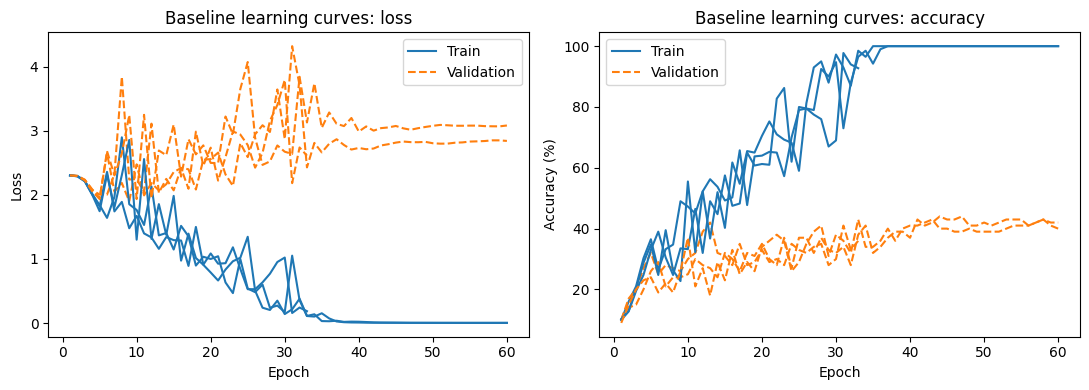

In [ ]:
CONFIGS = {
    "No augmentation":                  {},
    "Geometric only":                   dict(geo=1),
    "Photometric only":                 dict(photo=1),
    "Geometric + photometric":          dict(geo=1, photo=1),
    "+ Cutout / Random Erasing":        dict(geo=1, photo=1, cutout=1),
    "+ Mixup/CutMix + label smoothing": dict(geo=1, photo=1, cutout=1, mix=1, ls=0.1),
}
RESULTS["No augmentation"] = [run({}, s, HP) for s in SEEDS]
for k, name in [("train_acc", "Train"), ("val_acc", "Validation"), ("clean", "Clean test"), ("shifted", "Shifted test")]:
    print(f"{name:13s} accuracy: {stat('No augmentation', k)} %")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for i, r in enumerate(RESULTS["No augmentation"]):
    e = range(1, len(r["hist"]["val_acc"]) + 1)
    ax[0].plot(e, r["hist"]["train_loss"], "C0", label="Train" if i == 0 else None)
    ax[0].plot(e, r["hist"]["val_loss"], "C1--", label="Validation" if i == 0 else None)
    ax[1].plot(e, np.array(r["hist"]["train_acc"]) * 100, "C0", label="Train" if i == 0 else None)
    ax[1].plot(e, np.array(r["hist"]["val_acc"]) * 100, "C1--", label="Validation" if i == 0 else None)
ax[0].set(title="Baseline learning curves: loss", xlabel="Epoch", ylabel="Loss"); ax[1].set(title="Baseline learning curves: accuracy", xlabel="Epoch", ylabel="Accuracy (%)")
ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.show()

Diagnosis. In two of the three runs the training accuracy reaches 100% (the mean is 85.4 ± 25.3% only because one run was early-stopped and its best-validation checkpoint was restored), while validation accuracy stays near 43% and the validation loss rises from about 2 to about 3. This large train–validation gap shows the network memorized the 400 images (overfitting). Clean-test accuracy (40.6%) is also much higher than shifted-test accuracy (16.6%): the shifted images are rotated, darker or brighter, blurred, noisy, occluded and colour-changed, so they come from a different input distribution than the clean training images (covariate shift). The failure is therefore both: overfitting makes the model brittle, and the shift exposes it.

# Part B
Chosen augmentations (each matched to a corruption): **rotation/translation/scale + horizontal flip** (rotation), **brightness/contrast/saturation/grayscale/blur/noise** (brightness-contrast, blur, noise, unseen colour changes),
**Cutout / Random Erasing** (occlusion), **Mixup/CutMix + label smoothing** (regularisation on tiny data).

**Training settings:** rotation ±30°, translation ±10%, scale 0.9–1.1, horizontal flip, Cutout with p = 0.7, Mixup/CutMix on 50% of batches, label smoothing 0.1.

**1. Vertical flip: help or hurt?** It hurts. CIFAR-10 objects have a natural "up" (sky on top, wheels at the bottom) and neither training nor test images are upside down, so vertical flips teach unrealistic poses and remove orientation cues.
Horizontal flip is fine because mirrored objects are realistic and keep the label.I did not use vertical flip because it is not a realistic variation for this dataset, and it does not match any corruption in the shifted test.

**2. Rotation ±90° in training but ±25° at test:** the model is covered for the test range and gets more invariance, but about 72 % of the sampled rotations never occur at test time (1 − 25/90 ≈ 72 %), strong rotations make objects hard to recognise and create border artefacts,
and a small model spends capacity on useless cases, so accuracy on upright / slightly rotated images drops. A range slightly above the test range (±30°) is the better choice.

**3. Why too much augmentation reduces accuracy on a small model:** limited capacity cannot fit a very hard, very different training distribution (it underfits); heavy distortions can destroy the label evidence (a Cutout hiding the whole object, Mixup of ambiguous classes);
and BatchNorm statistics learned on heavily distorted batches mismatch the test images.

# Part C: Regularization and training design
| Technique | Placement | Justification |
|---|---|---|
| BatchNorm | after every convolution, before ReLU | stabilises training, allows higher learning rate, adds mild regularisation |
| Dropout | **after the FC layer only** | the dense FC layer is where memorisation happens; conv feature maps are spatially correlated, so dropping single activations in early convolutions removes little information and hurts low-level features |
| Global Average Pooling | instead of large FC layers | removes the huge parameter block that overfits |
| Weight decay (AdamW) | all weights | keeps weights small, smoother decision function |
| LR schedule (one-cycle) | warm-up then cosine decay | stable start, converges to a flat minimum |
| Early stopping | validation accuracy (best checkpoint restored) | stops when the model only memorises; uses validation data only |
| Label smoothing 0.1 | in the loss, with Mixup/CutMix | reduces over-confidence; consistent with the soft labels of mixed images |

# Part D:

In [ ]:
for name, cfg in CONFIGS.items():
    if name not in RESULTS: RESULTS[name] = [run(cfg, s, HP) for s in SEEDS]
best_name = max(CONFIGS, key=lambda n: np.mean([r["val_acc"] for r in RESULTS[n]]))
RESULTS["Final model"] = [run(CONFIGS[best_name], s, HP) for s in FINAL_SEEDS]
names = list(CONFIGS) + ["Final model"]
base = np.mean([r["shifted"] for r in RESULTS["No augmentation"]]) * 100
table = pd.DataFrame({"Configuration": names,
                      "Val Acc": [stat(n, "val_acc") for n in names],
                      "Clean Test": [stat(n, "clean") for n in names],
                      "Shifted Test": [stat(n, "shifted") for n in names],
                      "Shifted gain vs baseline": [f"{np.mean([r['shifted'] for r in RESULTS[n]]) * 100 - base:+.2f}" for n in names]})
print("final model configuration:", best_name); table

final model configuration: Photometric only


,Configuration,Val Acc,Clean Test,Shifted Test,Shifted gain vs baseline
0,No augmentation,43.00 ± 1.00,40.61 ± 3.85,16.60 ± 0.38,+0.00
1,Geometric only,39.67 ± 2.31,39.31 ± 1.43,16.92 ± 0.62,+0.32
2,Photometric only,44.00 ± 6.08,41.05 ± 1.50,19.09 ± 1.08,+2.49
3,Geometric + photometric,42.67 ± 2.52,40.26 ± 3.04,20.31 ± 0.32,+3.70
4,+ Cutout / Random Erasing,42.00 ± 1.00,38.13 ± 0.56,21.17 ± 0.26,+4.57
5,+ Mixup/CutMix + label smoothing,40.67 ± 3.21,38.64 ± 0.52,21.62 ± 0.62,+5.01
6,Final model,42.67 ± 2.31,40.94 ± 1.97,18.17 ± 1.16,+1.56


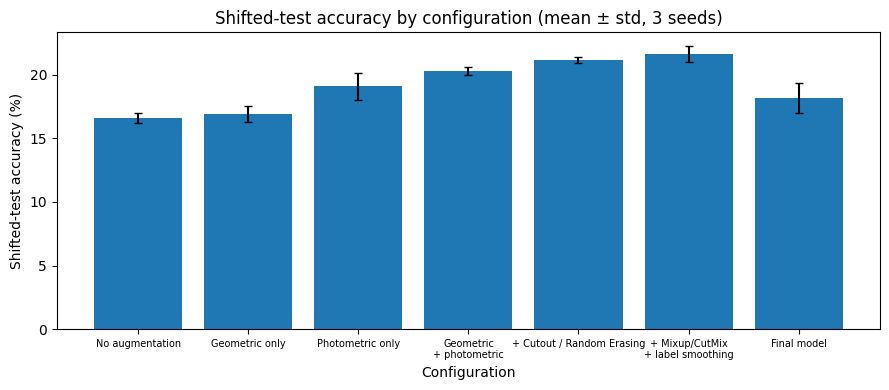

In [ ]:
m = [np.mean([r["shifted"] for r in RESULTS[n]]) * 100 for n in names]; s = [np.std([r["shifted"] for r in RESULTS[n]], ddof=1) * 100 for n in names]
plt.figure(figsize=(9, 4)); plt.bar(range(len(names)), m, yerr=s, capsize=3)
plt.xticks(range(len(names)), [n.replace(" + ", "\n+ ") for n in names], fontsize=7)
plt.title("Shifted-test accuracy by configuration (mean ± std, 3 seeds)"); plt.xlabel("Configuration"); plt.ylabel("Shifted-test accuracy (%)"); plt.tight_layout(); plt.show()

**Which augmentation gave the largest gain?** Photometric augmentation (brightness/contrast/saturation jitter, grayscale, blur, noise) gave the largest single gain: +2.49 points over the baseline (16.60% → 19.09% shifted accuracy). It matches the brightness/contrast change, blur and noise in the shifted test, and its saturation and grayscale jitter also help against the unseen colour corruption, since the model learns not to depend on exact colours. Geometric augmentation alone helped very little (+0.32), even though the test has ±25° rotations. Combining geometric and photometric gave a further +1.22, Cutout / Random Erasing +0.86 (it matches the ~25% occlusion, so the network can no longer rely on one patch), and Mixup/CutMix + label smoothing +0.45. The last two gains are smaller than or close to the seed-to-seed std (about 0.3–0.6), so they should not be over-interpreted. Overall, the full recipe raised shifted accuracy from 16.60% to 21.62% (+5.01 points), while clean-test accuracy stayed about the same (38–41%), so augmentation mainly improved robustness to the shift and not clean accuracy.

The final model was chosen by validation accuracy only (as required, never by test results), which selected "Photometric only"; re-trained with fresh seeds it scored 18.17 ± 1.16% shifted. Validation accuracy on only 100 images is noisy (std up to 6 points), so it could not reliably separate the configurations.

# Part E:

     Class  Accuracy (%)
  airplane          17.5
automobile           8.9
      bird          10.7
       cat          29.8
      deer          20.2
       dog          12.2
      frog          11.5
     horse          18.8
      ship          27.8
     truck          30.0


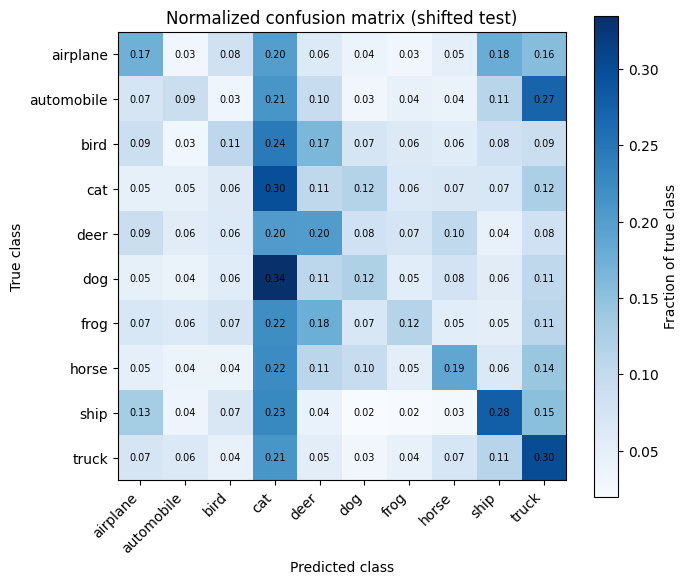

Most confused pairs (true -> predicted):
  dog -> cat: 33.5 %
  automobile -> truck: 27.2 %
  bird -> cat: 24.5 %
  ship -> cat: 22.7 %
  horse -> cat: 22.4 %


In [ ]:
FINAL = RESULTS["Final model"]; model = FINAL[0]["model"]
model.eval()
with torch.no_grad(): pred = torch.cat([model(X_shift[i:i + 1000].to(device)).argmax(1).cpu() for i in range(0, len(X_shift), 1000)]).numpy()
yt = y_shift.numpy()
cm = np.zeros((10, 10))
for t, p in zip(yt, pred): cm[t, p] += 1
cmn = cm / cm.sum(1, keepdims=True)
print(pd.DataFrame({"Class": CLASSES, "Accuracy (%)": (np.diag(cmn) * 100).round(1)}).to_string(index=False))

plt.figure(figsize=(7, 6)); plt.imshow(cmn, cmap="Blues")
plt.xticks(range(10), CLASSES, rotation=45, ha="right"); plt.yticks(range(10), CLASSES)
for i in range(10):
    for j in range(10): plt.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if cmn[i, j] > .5 else "black")
plt.colorbar(label="Fraction of true class"); plt.title("Normalized confusion matrix (shifted test)"); plt.xlabel("Predicted class"); plt.ylabel("True class"); plt.tight_layout(); plt.show()

print("Most confused pairs (true -> predicted):")
for v, a, b in sorted([(cmn[i, j], CLASSES[i], CLASSES[j]) for i in range(10) for j in range(10) if i != j], reverse=True)[:5]:
    print(f"  {a} -> {b}: {v * 100:.1f} %")

**Most confused classes and why:** The model is strongly biased toward predicting **cat** on the shifted test set: about 24% of all shifted images are labelled cat (vs. 10% expected), and four of the five most confused pairs end in cat (dog→cat 33.5%, bird→cat 24.5%, ship→cat 22.7%, horse→cat 22.4%). Cat's own accuracy (29.8%) is therefore inflated by over-prediction. A likely reason is that when blur, noise, darkness/brightness, occlusion and colour changes remove the distinguishing details, the model falls back to the class whose training images are the most varied and low-detail. The other main confusion is automobile→truck (27.2%), a genuine look-alike pair with similar shape and colour. The worst classes are automobile (8.9%), bird (10.7%), frog (11.5%) and dog (12.2%); the best are truck (30.0%), cat (29.8%) and ship (27.8%).

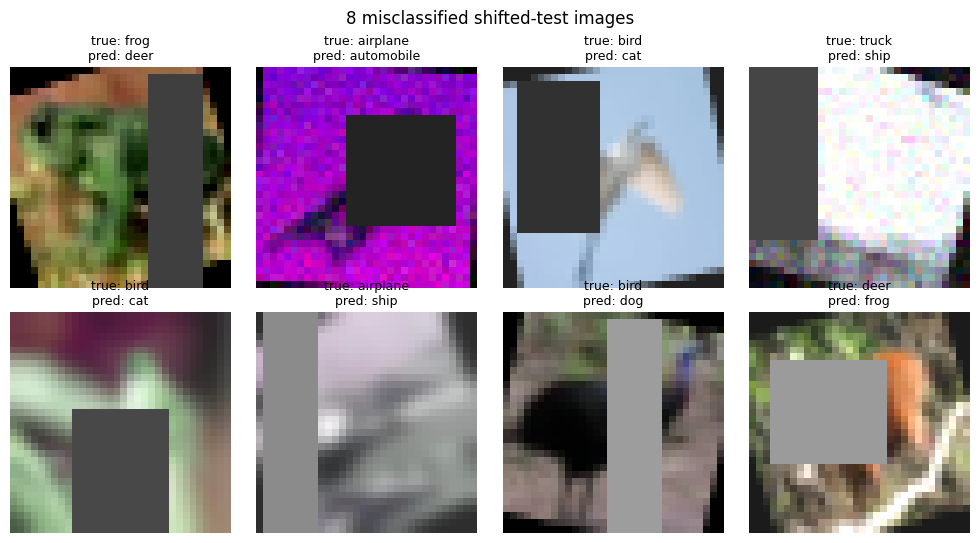

In [ ]:
wrong = np.where(pred != yt)[0]; pick = np.random.RandomState(0).choice(wrong, 8, replace=False)
fig, ax = plt.subplots(2, 4, figsize=(10, 5.5))
for a, i in zip(ax.ravel(), pick):
    a.imshow(X_shift[i].permute(1, 2, 0)); a.axis("off"); a.set_title(f"true: {CLASSES[yt[i]]}\npred: {CLASSES[pred[i]]}", fontsize=9)
plt.suptitle("8 misclassified shifted-test images"); plt.tight_layout(); plt.show()

| # | True → Predicted | Visual property that caused the failure |
|---|---|---|
| 1 | frog → deer | Rotated (black corners) and a tall occluder hides part of the frog; the remaining blurry green-brown texture resembles a deer in grass. |
| 2 | airplane → automobile | Wrong colours (magenta sky, probably the hidden colour swap), strong noise, and the occluder covers the centre where the plane is. |
| 3 | bird → cat | A large occluder hides almost half the image and it is rotated; the bird is small, pale and blurry against a pale sky. |
| 4 | truck → ship | Extremely bright and washed out with noise speckles, plus an occluder and rotation; almost no contrast, and the white background looks like sky or sea. |
| 5 | bird → cat | Heavy blur with strange purple/green colours (likely colour swap), so shape and texture are lost. |
| 6 | airplane → ship | Low contrast, grey-pink and blurry with a vertical occluder; a whitish object on grey looks like a ship on water. |
| 7 | bird → dog | Dark, rotated image and an occluder covers part of the bird; the dark body on a brown background looks like a dog. |
| 8 | deer → frog | The deer is mostly behind a large occluder; the visible green-brown vegetation looks like a frog scene. |

In [ ]:

X_hid = make_shifted(X_clean, seed=77, only_swap=True, p_swap=1.0)
for name in ["No augmentation", "Final model"]:
    c = np.array([evaluate(r["model"], X_clean, y_clean)[1] for r in RESULTS[name]]) * 100
    h = np.array([evaluate(r["model"], X_hid, y_clean)[1] for r in RESULTS[name]]) * 100
    print(f"{name:16s} clean {c.mean():.2f} | channel-swap only {h.mean():.2f} ± {h.std(ddof=1):.2f} | drop {c.mean() - h.mean():.2f} pts")

No augmentation  clean 40.61 | channel-swap only 26.69 ± 3.17 | drop 13.92 pts
Final model      clean 40.94 | channel-swap only 25.42 ± 1.17 | drop 15.52 pts


**Did the augmentation generalize to the hidden corruption?** No. When only the colour-channel swap is applied to the clean test set, the baseline drops from 40.61% to 26.69 ± 3.17% (−13.92 points) and the final model (photometric augmentation) drops from 40.94% to 25.42 ± 1.17% (−15.52 points). The difference between the two drops is within the seed-to-seed standard deviation, so the augmentation gave no measurable robustness to this corruption. Our colour augmentations (brightness, contrast and saturation jitter, 10% random grayscale) change how strong or pale colours are, but they never swap which channel carries which colour, so the model still relies on the original hue of objects (blue sky and sea for airplane and ship, green for frog, brown for deer and horse). Augmentation generalizes only to variations that resemble what was trained on; it does not automatically cover a new kind of change. Making the model robust to unseen colour changes would need more diverse colour augmentation (for example hue jitter, a higher grayscale probability, or random channel dropout). Training on the exact channel swap would defeat the purpose of a hidden corruption. The channel swap alone costs about 15 points, while the full shifted test costs about 22 points (40.9% → 18.2%), so the other corruptions (rotation, occlusion, blur, noise) account for the rest.

# Part F (bonus):

In [ ]:
def shift(x, dy, dx): return F.pad(x, (2, 2, 2, 2), mode="reflect")[:, :, 2 + dy:34 + dy, 2 + dx:34 + dx]
def views(x): return [x, x.flip(3)] + [shift(x, dy, dx) for dy, dx in [(2, 0), (-2, 0), (0, 2), (0, -2)]] + [shift(x, 0, 2).flip(3), shift(x, 0, -2).flip(3)]

def predict(model, X, tta):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), 1000):
            xb = X[i:i + 1000].to(device)
            out.append(torch.stack([F.softmax(model(v), 1) for v in (views(xb) if tta else [xb])]).mean(0))
    return torch.cat(out)

plain, tta, t_plain, t_tta = [], [], [], []
for r in FINAL:
    for use, accs, times in [(False, plain, t_plain), (True, tta, t_tta)]:
        t0 = time.time(); p = predict(r["model"], X_shift, use); times.append(time.time() - t0)
        accs.append((p.argmax(1).cpu() == y_shift).float().mean().item() * 100)
print(f"Shifted accuracy without TTA: {np.mean(plain):.2f} ± {np.std(plain, ddof=1):.2f}")
print(f"Shifted accuracy with TTA   : {np.mean(tta):.2f} ± {np.std(tta, ddof=1):.2f}  (change {np.mean(tta) - np.mean(plain):+.2f} points)")
print(f"Inference cost: 8 forward passes per image, measured time x{np.mean(t_tta) / np.mean(t_plain):.1f}")

Shifted accuracy without TTA: 18.17 ± 1.16
Shifted accuracy with TTA   : 18.72 ± 1.54  (change +0.55 points)
Inference cost: 8 forward passes per image, measured time x7.2


**Test-time augmentation result.** Averaging the softmax over 8 views (original, horizontal flip, four ±2-pixel shifts, two flipped shifts) changed shifted-test accuracy from 18.17 ± 1.16% to 18.72 ± 1.54% (+0.55 points). The gain is smaller than the seed-to-seed standard deviation, so it is a small, not statistically clear, improvement. A likely reason is that the final model (photometric augmentation only) was never trained with flips or shifts, so those views are slightly unfamiliar to it, and TTA cannot restore information that the corruptions removed (an occluded object, heavy blur, swapped colours). **Inference cost:** 8 forward passes per image, so 8× the computation; the measured time was 7.2× higher.

# Numbers for the one-page Word summary

In [ ]:
print("Final shifted-test accuracy:", stat("Final model", "shifted"), "%  | clean:", stat("Final model", "clean"), "%")
print("Final configuration:", best_name, "| hyper-parameters:", HP, "| parameters:", n_params)
print("Single change that helped most: the row with the largest 'Shifted gain' in the Part D table")

Final shifted-test accuracy: 18.17 ± 1.16 %  | clean: 40.94 ± 1.97 %
Final configuration: Photometric only | hyper-parameters: {'lr': 0.003, 'wd': 0.01, 'dropout': 0.4} | parameters: 142970
Single change that helped most: the row with the largest 'Shifted gain' in the Part D table
